# Сегментация повреждений автомобиля

Укажите PNG из папки `../outputs` в `IMAGE_PATH` и запустите ячейки сверху вниз.

## 1. Настройки и загрузка модели

In [29]:
from collections import Counter
from pathlib import Path

import torch
from IPython.display import display
from PIL import Image, ImageOps
from ultralytics import YOLO

MODEL_PATH = Path("../models/damage segmentation.pt")
IMAGE_PATH = Path("../outputs/1.png")
IMAGE_SIZE = 640
CONFIDENCE_THRESHOLD = 0.25
DEVICE = 0 if torch.cuda.is_available() else "cpu"

model = YOLO(str(MODEL_PATH))

## 2. Загрузка фото

In [30]:
with Image.open(IMAGE_PATH) as source:
    image = ImageOps.exif_transpose(source).convert("RGB")

## 3. Поиск повреждений

In [31]:
result = model.predict(
    source=image,
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE_THRESHOLD,
    device=DEVICE,
    retina_masks=True,
    verbose=False,
)[0]

## 4. Маски, уверенность и количество повреждений

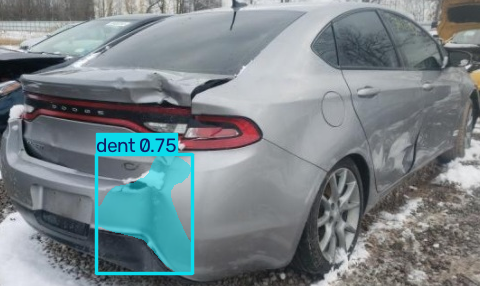

Найденные повреждения: вмятина - 1


In [32]:
damage_names = {
    "crack": "трещина",
    "dent": "вмятина",
    "glass shatter": "разбитое стекло",
    "lamp broken": "разбитая фара",
    "scratch": "царапина",
    "tire flat": "спущенная шина",
}

def show_segmentation(result, labels):
    annotated_bgr = result.plot(masks=True, conf=True)
    display(Image.fromarray(annotated_bgr[..., ::-1]))

    counts = Counter(result.boxes.cls.int().tolist())
    if counts:
        summary = "; ".join(
            f"{labels[result.names[class_id]]} - {count}"
            for class_id, count in sorted(counts.items())
        )
        print(f"Найденные повреждения: {summary}")
    else:
        print("Повреждения не найдены")


show_segmentation(result, damage_names)

## 5. YOLOE по текстовым описаниям

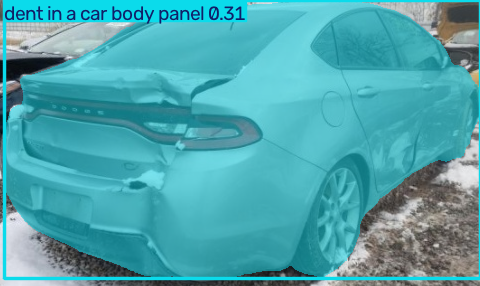

Найденные повреждения: вмятина - 1


In [33]:
from ultralytics import YOLOE

YOLOE_PATH = Path("../models/yoloe-11s-seg.pt")
YOLOE_PROMPTS_PATH = Path("../models/yoloe-11s-damage-prompts.npz")
yoloe_prompts = {
    "crack": "crack in a car body panel",
    "dent": "dent in a car body panel",
    "glass shatter": "shattered car window",
    "lamp broken": "broken car headlight or taillight",
    "scratch": "scratch in car paint",
    "tire flat": "flat car tire",
}

yoloe_model = YOLOE(str(YOLOE_PATH))
yoloe_model.load_prompt_embeddings(YOLOE_PROMPTS_PATH)

yoloe_result = yoloe_model.predict(
    source=image,
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE_THRESHOLD,
    device=DEVICE,
    retina_masks=True,
    verbose=False,
)[0]
yoloe_labels = {prompt: damage_names[label] for label, prompt in yoloe_prompts.items()}
show_segmentation(yoloe_result, yoloe_labels)

## 6. Оценка классов через CLIP

In [34]:
from transformers import CLIPModel, CLIPProcessor

ZERO_SHOT_THRESHOLD = 0.60
text_device = torch.device(f"cuda:{DEVICE}" if isinstance(DEVICE, int) else DEVICE)

damage_prompt_pairs = {
    "crack": ("a cracked car body panel", "an intact car body panel"),
    "dent": ("a dented car body panel", "a smooth undented car body panel"),
    "glass shatter": ("a shattered car window", "an intact car window"),
    "lamp broken": ("a broken car headlight or taillight", "an intact car headlight or taillight"),
    "scratch": ("scratches in car paint", "smooth car paint with no scratches"),
    "tire flat": ("a flat car tire", "a properly inflated car tire"),
}
damage_prompts = [
    f"a photo of {description}"
    for pair in damage_prompt_pairs.values()
    for description in pair
]


def show_zero_shot_scores(logits):
    scores = logits.reshape(-1, 2).softmax(dim=1)[:, 0].tolist()
    flagged = []
    for label, score in zip(damage_prompt_pairs, scores):
        name = damage_names[label]
        print(f"{name} - {score:.2%}")
        if score >= ZERO_SHOT_THRESHOLD:
            flagged.append(name)
    summary = "; ".join(flagged) if flagged else "нет"
    print(f"Классы выше порога {ZERO_SHOT_THRESHOLD:.0%}: {summary}")


clip_id = "openai/clip-vit-base-patch32"
clip_cache = Path("../models/clip")
clip_processor = CLIPProcessor.from_pretrained(clip_id, cache_dir=clip_cache)
clip_model = CLIPModel.from_pretrained(clip_id, cache_dir=clip_cache, use_safetensors=False).to(text_device).eval()

clip_size = clip_model.config.vision_config.image_size
model_image = ImageOps.pad(image, (clip_size, clip_size), color=(127, 127, 127))
clip_inputs = clip_processor(text=damage_prompts, images=model_image, padding=True, return_tensors="pt").to(text_device)

with torch.inference_mode():
    clip_logits = clip_model(**clip_inputs).logits_per_image[0]

show_zero_shot_scores(clip_logits)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 920.02it/s, Materializing param=visual_projection.weight]                                
CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


трещина - 16.45%
вмятина - 77.97%
разбитое стекло - 14.23%
разбитая фара - 53.92%
царапина - 57.85%
спущенная шина - 15.08%
Классы выше порога 60%: вмятина


## 7. Оценка классов через SigLIP 2

Используем то же фото, те же пары описаний и тот же порог.

In [35]:
from transformers import AutoImageProcessor, AutoModel, GemmaTokenizer, SiglipProcessor

siglip_id = "google/siglip2-base-patch16-224"
siglip_cache = Path("../models/siglip2")
siglip_image_processor = AutoImageProcessor.from_pretrained(siglip_id, cache_dir=siglip_cache)
siglip_tokenizer = GemmaTokenizer.from_pretrained(siglip_id, cache_dir=siglip_cache)
siglip_processor = SiglipProcessor(siglip_image_processor, siglip_tokenizer)
siglip_model = AutoModel.from_pretrained(siglip_id, cache_dir=siglip_cache).to(text_device).eval()

siglip_inputs = siglip_processor(
    text=damage_prompts, images=model_image, padding="max_length", max_length=64, return_tensors="pt",
).to(text_device)

with torch.inference_mode():
    siglip_logits = siglip_model(**siglip_inputs).logits_per_image[0]

show_zero_shot_scores(siglip_logits)

Loading weights: 100%|██████████| 408/408 [00:00<00:00, 745.07it/s, Materializing param=vision_model.post_layernorm.weight]                      


трещина - 43.79%
вмятина - 97.47%
разбитое стекло - 4.49%
разбитая фара - 58.31%
царапина - 68.72%
спущенная шина - 86.03%
Классы выше порога 60%: вмятина; царапина; спущенная шина
